# CampusPulse: Conclusions
**Umbrella question:** *Can routine campus data (records, clicks, surveys, sales, meters) warn a university early
enough to act, and how much do those warnings depend on our data-cleaning decisions?*

Five real datasets, one shared method: every pulse logs its cleaning decisions and re-computes its headline
findings under every alternative choice (the **Finding Robustness Matrix**).

| Pulse | Question | Dataset |
|---|---|---|
| ① Academic | Who drops out, and how early can we tell? | UCI 697, Portuguese polytechnic, 4,424 students |
| ② Engagement | From which week do platform clicks predict withdrawal? | OULAD, Open University UK, 32,593 students |
| ③ Wellbeing | Which behaviours co-occur with persistent sadness? | CDC YRBS + Malaysia university survey (n=101) |
| ④ Food | Does offering more vegetarian meals cost sales? | NOVANIMAL, 2 Swiss university canteens, randomised |
| ⑤ Energy | When does a campus building behave differently? | I-BLEND, IIIT Delhi, 52 months of meter data + teaching calendar |

> Every number below is computed by the code cells in this notebook, not typed in.

## 1. What each pulse actually implements (syllabus coverage)

| Lecture topic | ① Academic | ② Engagement | ③ Wellbeing | ④ Food | ⑤ Energy |
|:---|:---|:---|:---|:---|:---|
| L2 Collecting & storing | CSV + header fixes | 10.6M click events → weekly table | CDC export → CSV | 26k till records | 1-min meters → hourly table |
| L3–4 One/two-variable stats | dropout rates by group | clicks vs withdrawal | sleep vs sadness | daily sales, veg share | exam vs normal nights |
| L5 Noise removal / smoothing | — | 2-week rolling, exponential | — | **weekday adjustment** vs rolling | 3-h rolling median |
| L6–7 Outliers | IQR on age | — | — | **IQR outlier days**: keep / drop / winsorize | 99th-pct clipping vs raw |
| L7–8 Missing values | **ungraded 0s = MNAR** | missing early scores | **skipped sensitive answers** | — | **meter gaps**: interpolate / ffill / drop |
| L9 Text features | — | — | **course-name normalisation** (49 → 7) | menu keyword flags | — |
| L11 Shape transformation | one-hot of coded categories | long logs → wide weekly matrix | binary behaviour matrix | transactions → daily × meal type | **series → day × 24-h matrix** |
| L12–13 Encoding, PCA, SVD | PCA (quantities), SVD (one-hot) | PCA, SVD | PCA, SVD | PCA, SVD | PCA, SVD |
| L14 t-SNE | ✓ | ✓ | ✓ | — | ✓ |
| L16 Autoencoder | anomaly score | — | — | — | **anomaly score on daily profiles** |
| L18 Association rules | → dropout | → withdrawal | → sadness | → vegetarian choice | → high demand |
| L19–21 Clustering | K-Means, Ward, DBSCAN, OPTICS (scaled) | same | same | same | same |
| Hypothesis tests | χ², z, Welch t, ANOVA, stratified χ² | χ², z, Welch t | χ² + Bonferroni, survey weights | **non-inferiority t**, Welch t, χ² | Welch t, **same-month t** |

## 2. Headline findings and their robustness (computed)

In [1]:
import sys, os
from pathlib import Path
for cand in [Path.cwd(), Path.cwd().parent]:
    if (cand / 'campuspulse').exists():
        sys.path.insert(0, str(cand)); break
os.environ['LOKY_MAX_CPU_COUNT'] = '1'

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from campuspulse.academic import pipeline as A
from campuspulse.engagement import pipeline as E
from campuspulse.wellbeing import pipeline as W
from campuspulse.food import pipeline as F
from campuspulse.energy import pipeline as EN
from campuspulse.common.decisions import (robustness_matrix, heatmap, survival_summary,
                                          fragility_table, status_matrix, defaults)
from campuspulse.common.plots import theme
theme()
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 90)

PULSES = {"① Academic": A, "② Engagement": E, "③ Wellbeing": W, "④ Food": F, "⑤ Energy": EN}
VALUES, MISSING = {}, []
for name, P in PULSES.items():
    try:
        VALUES[name] = robustness_matrix(P.run_pipeline, P.DECISIONS, P.FINDINGS)[0]
    except FileNotFoundError as e:
        MISSING.append(name)
print("Pulses computed:", list(VALUES))
print("Pulses with data missing on this machine:", MISSING or "none")

rows = []
for name, vals in VALUES.items():
    P = PULSES[name]
    stat = status_matrix(vals).drop(columns="DEFAULT")
    for fid, claim in P.FINDINGS.items():
        s = stat.loc[fid]
        tested = (s != "n/a").sum()
        rows.append({"pulse": name, "finding": fid, "claim": claim, "default value": round(vals.loc[fid, "DEFAULT"], 3),
                     "holds": f"{(s == 'holds').sum()}/{tested}",
                     "moves under": ", ".join(f"{c} ({s[c]})" for c in s.index if s[c] in ("weakens", "inflates", "reverses")) or "-"})
master = pd.DataFrame(rows)
master

Pulses computed: ['① Academic', '② Engagement', '③ Wellbeing', '④ Food', '⑤ Energy']
Pulses with data missing on this machine: none


In [2]:
print(master.to_string(index=False))

       pulse finding                                                                                                                                               claim  default value holds                                                                                                                     moves under
  ① Academic      A1                                                                                            Debtors drop out more than non-debtors (rate difference)          0.411   4/4                                                                                                                               -
  ① Academic      A2                                                                                                 Scholarship holders drop out less (rate difference)          0.345   4/4                                                                                                                               -
  ① Academic      A3                          

## 3. How fragile are campus insights?
A finding **holds** if it keeps its sign and stays between ½× and 2× of our default under an alternative choice.
**Inflates** (> 2×) is a warning, not good news: the cleaning choice is creating most of the effect.

              tested  holds  weakens  inflates  reverses  n/a  survival_rate
① Academic      16.0   15.0      0.0       1.0       0.0  0.0       0.937500
② Engagement    21.0   12.0      1.0       6.0       2.0  0.0       0.571429
③ Wellbeing     24.0   23.0      0.0       1.0       0.0  0.0       0.958333
④ Food          16.0   13.0      1.0       0.0       2.0  2.0       0.812500
⑤ Energy        15.0   14.0      1.0       0.0       0.0  0.0       0.933333

Fragility leaderboard (most fragile first):
       pulse finding                           worst_variant   default  worst_value     change verdict
      ④ Food      F1                         seasonality=raw     8.651       -5.948 sign flips fragile
② Engagement      E2                    already_left=include     1.677       -0.273 sign flips fragile
② Engagement      E3                     early_cutoff=week_2     0.037       -0.260 sign flips fragile
② Engagement      E1                    already_left=include     0.071        0.4

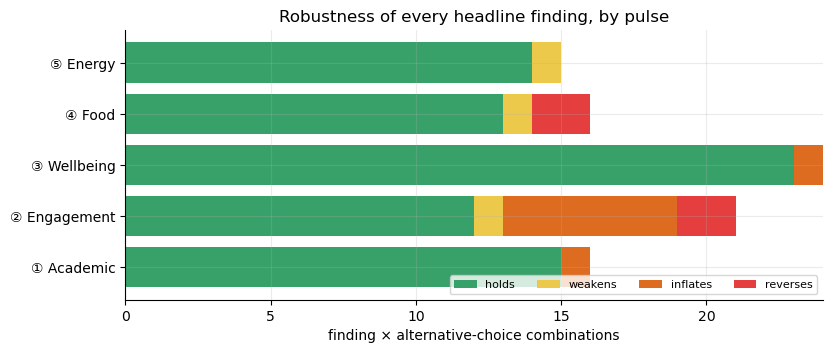

In [3]:
summary = pd.DataFrame({name: survival_summary(v) for name, v in VALUES.items()}).T
print(summary[["tested", "holds", "weakens", "inflates", "reverses", "n/a", "survival_rate"]].to_string())

board = pd.concat([fragility_table(v, PULSES[n].FINDINGS).assign(pulse=n) for n, v in VALUES.items()])
board = board.sort_values("swing", ascending=False)
print("\nFragility leaderboard (most fragile first):")
print(board[["pulse", "finding", "worst_variant", "default", "worst_value", "change", "verdict"]].round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 3.5))
order = ["holds", "weakens", "inflates", "reverses"]
colours = {"holds": "#38a169", "weakens": "#ecc94b", "inflates": "#dd6b20", "reverses": "#e53e3e"}
left = np.zeros(len(summary))
for s in order:
    ax.barh(summary.index, summary[s], left=left, color=colours[s], label=s)
    left += summary[s].values
ax.set_xlabel("finding × alternative-choice combinations")
ax.set_title("Robustness of every headline finding, by pulse")
ax.legend(ncol=4, loc="lower right", fontsize=8)
plt.show()

## 4. How early can a university warn? (① ↔ ②)
Same metric for both institutions: if the university contacts the **25% highest-risk students**, what share of
all eventual dropouts/withdrawals does it reach (*capture@25%*)?

                institution              stage  roc_auc  capture_at_25pct  max_possible_capture  precision_at_25pct
          Portugal (campus)     1 at enrolment    0.852             0.541                 0.639               0.847
          Portugal (campus) 2 after semester 1    0.935             0.626                 0.639               0.980
          Portugal (campus) 3 after semester 2    0.949             0.634                 0.639               0.992
Open University UK (online)             week_2    0.570             0.307                 1.000               0.240
Open University UK (online)             week_4    0.558             0.290                 1.000               0.205
Open University UK (online)             week_6    0.563             0.296                 1.000               0.192


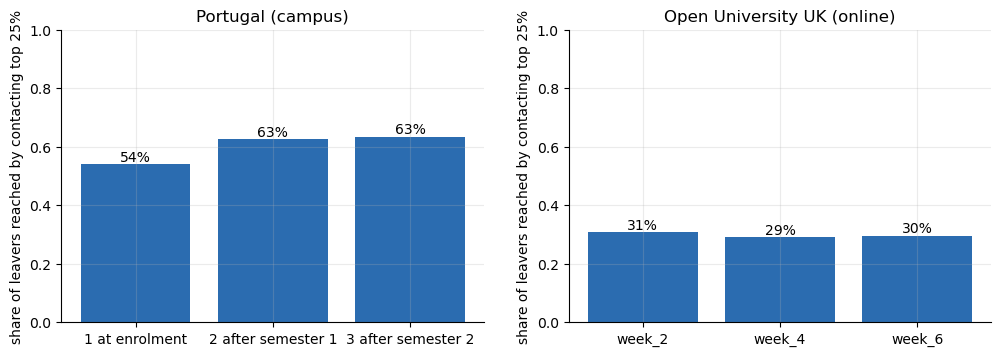

In [4]:
tl = []
try:
    tl.append(A.run_timeline(A.clean(defaults(A.DECISIONS))).assign(institution="Portugal (campus)"))
except FileNotFoundError:
    print("Academic data missing")
try:
    tl.append(E.run_timeline().assign(institution="Open University UK (online)"))
except FileNotFoundError:
    print("Engagement data missing")
if tl:
    timeline = pd.concat(tl, ignore_index=True)
    print(timeline[["institution", "stage", "roc_auc", "capture_at_25pct", "max_possible_capture", "precision_at_25pct"]].round(3).to_string(index=False))
    fig, axes = plt.subplots(1, len(tl), figsize=(6 * len(tl), 3.8), squeeze=False)
    for ax, (inst, g) in zip(axes[0], timeline.groupby("institution", sort=False)):
        ax.bar(g["stage"].astype(str), g["capture_at_25pct"], color="#2b6cb0")
        for i, v in enumerate(g["capture_at_25pct"]):
            ax.text(i, v + 0.01, f"{v:.0%}", ha="center")
        ax.set_ylim(0, 1); ax.set_title(inst); ax.set_ylabel("share of leavers reached by contacting top 25%")
    plt.show()

## 5. Does money matter beyond grades? (① finding A4)
Debtor vs non-debtor dropout gap **inside** each semester-1 approval-rate band.

In [5]:
try:
    _, strat = A.stratified_debt_effect(A.clean(defaults(A.DECISIONS)))
    print(strat.round(3).to_string(index=False))
except FileNotFoundError:
    print("Academic data missing")

       band    n  n_debtors   gap  cramers_v
low (<=50%)  808        174 0.019      0.045
        mid 1124        118 0.481      0.305
 all passed 1546        101 0.213      0.173


## 6. Testing our own claim: is the term effect just the season? (⑤ EN2 vs EN3)
The I-BLEND calendar marks teaching days and vacations but not exams. Delhi's long vacation is also its hottest season,
so EN3 compares term and vacation nights only within the same calendar month.

In [6]:
try:
    df_en = EN.clean(defaults(EN.DECISIONS))
    st_en = EN.run_stats(df_en)
    print("Teaching vs low-activity days (academic building):", {k: round(float(v), 3) for k, v in st_en["teaching_t"].items()})
    print("Term vs vacation nights (hostels):                ", {k: round(float(v), 3) for k, v in st_en["term_t"].items()})
    print("Same month only:                                  ", {k: (round(float(v), 3) if pd.notna(v) else v) for k, v in st_en["within_month_t"].items()})
    print(st_en["by_month"].round(0).to_string(index=False))
except FileNotFoundError:
    print("Energy data missing")

Teaching vs low-activity days (academic building): {'diff': 17857.608, 't': 63.214, 'p': 0.0, 'cohens_d': 1.319}
Term vs vacation nights (hostels):                 {'diff': 12169.475, 't': 31.631, 'p': 0.0, 'cohens_d': 0.972}
Same month only:                                   {'n_months': 7.0, 'mean_diff': 8108.379, 't': 2.305, 'p': 0.061, 'share_months_positive': 0.714}
  month  term_rows  vacation_rows  term_mean  vacation_mean    diff
2013-11        145              5    34797.0        40619.0 -5822.0
2014-01        130             18    52968.0        37388.0 15580.0
2014-11        100             10    47767.0        42957.0  4809.0
2015-01         90             15    56940.0        42672.0 14268.0
2017-01        150              5    54649.0        34288.0 20361.0
2017-04        140              5    76106.0        76424.0  -318.0
2017-11        145              5    42337.0        34456.0  7881.0


## 7. The one causal result: the canteen experiment (④)

In [7]:
for seas in F.DECISIONS["seasonality"]:
    cfg = {**defaults(F.DECISIONS), "seasonality": seas}
    ni = F.run_stats(F.clean(cfg), cfg)["sales_non_inferiority"]
    print(f"{seas:17s} diff {ni['diff']:+6.1f} meals/day | lower 95% bound {ni['lower_95']:+6.1f} | margin -{ni['margin']:.1f} | "
          f"{'NON-INFERIOR' if ni['non_inferior'] else 'not proven'}")

weekday_adjusted  diff   +0.5 meals/day | lower 95% bound  -11.4 | margin -20.1 | NON-INFERIOR
raw               diff   +0.5 meals/day | lower 95% bound  -26.0 | margin -20.1 | not proven
rolling_5day      diff   -6.7 meals/day | lower 95% bound  -14.0 | margin -20.4 | NON-INFERIOR


## 8. Limitations, implications and next steps

**Limitations**
- Five institutions in four countries, none of them ours. We compare *conclusions*, never join rows across datasets.
- Only ④ is a randomised experiment; every other finding is an association.
- YRBS is a high-school survey; the Malaysia survey has n = 101, so W4 is exploratory.
- The energy ↔ wellbeing link is indirect: hostel power is not a measurement of sleep, and the I-BLEND calendar has no exam dates.
- The robustness matrix changes one decision at a time; interactions between decisions are not tested.
- The OULAD, YRBS and I-BLEND preprocessing (raw → processed tables) must be re-run to reproduce ②, ③, ⑤ exactly.

**Implications (only where the computed results above support them)**
- If capture@25% after semester 1 / week 2–4 is high, a small, targeted outreach list reaches most future leavers.
- Fee status and scholarships are cheap, actionable signals, but A4 shows *where* they matter (by grade band).
- A cleaning choice can create or hide most of an effect (see the fragility leaderboard), so institutional
  dashboards should publish their cleaning decisions next to their numbers.

**Next steps**
- Indian institutional data (AISHE / own university, with ethics approval) to test which signals transfer.
- Test decision interactions (full factorial), not only one-at-a-time changes.
- Survey-design-based tests (Rao–Scott χ²) for YRBS instead of weighted rates only.